<a href="https://colab.research.google.com/github/sawantarya232-blip/Deep-Learning/blob/main/Assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q librosa soundfile scikit-learn transformers gTTS jiwer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1,000.0/1,000.0 kB 25.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 36.4 MB/s eta 0:00:00


In [2]:
import os
import gc
import time
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix
)
from transformers import pipeline
from gtts import gTTS
from jiwer import wer
from google.colab import files
from IPython.display import Audio, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [3]:
url = "https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip"

if not os.path.exists("ESC-50-master"):
    urllib.request.urlretrieve(url, "esc50.zip")

    with zipfile.ZipFile("esc50.zip", "r") as zip_ref:
        zip_ref.extractall(".")

print("Dataset downloaded.")

Dataset downloaded.


In [4]:
data_dir = "ESC-50-master"
metadata = pd.read_csv(
    os.path.join(data_dir, "meta", "esc50.csv")
)

# Select 10 clips from each of the 50 classes
subset = (
    metadata.groupby("category", group_keys=False)
    .sample(n=10, random_state=42)
    .reset_index(drop=True)
)

train_df, test_df = train_test_split(
    subset,
    test_size=0.20,
    random_state=42,
    stratify=subset["category"]
)

classes = sorted(subset["category"].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}

print("Total subset:", len(subset))
print("Training clips:", len(train_df))
print("Testing clips:", len(test_df))
print("Number of classes:", len(classes))

Total subset: 500
Training clips: 400
Testing clips: 100
Number of classes: 50


In [5]:
class AudioDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        path = os.path.join(
            data_dir, "audio", row["filename"]
        )

        audio, sr = librosa.load(
            path, sr=22050, duration=5.0
        )

        mel = librosa.feature.melspectrogram(
            y=audio,
            sr=sr,
            n_fft=1024,
            hop_length=512,
            n_mels=64
        )

        mel = librosa.power_to_db(mel, ref=np.max)
        mel = (mel + 80) / 80

        mel = torch.tensor(
            mel, dtype=torch.float32
        ).unsqueeze(0)

        label = class_to_idx[row["category"]]

        return mel, label


train_dataset = AudioDataset(train_df)
test_dataset = AudioDataset(test_df)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False,
    num_workers=0
)

print("Data loaders ready.")

Data loaders ready.


In [6]:
class AudioCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = AudioCNN(len(classes)).to(device)
print(model)

AudioCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=50, bias=True)
  )
)


In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

history = {"loss": [], "accuracy": []}
start_time = time.time()

for epoch in range(5):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for mel, labels in train_loader:
        mel = mel.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(mel)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = 100 * correct / total

    history["loss"].append(epoch_loss)
    history["accuracy"].append(epoch_accuracy)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

training_time = time.time() - start_time
print("Training time:", round(training_time, 2), "seconds")

Epoch 1/5 | Loss: 3.9196 | Accuracy: 1.00%
Epoch 2/5 | Loss: 3.9037 | Accuracy: 3.50%
Epoch 3/5 | Loss: 3.7922 | Accuracy: 2.75%
Epoch 4/5 | Loss: 3.6313 | Accuracy: 5.75%
Epoch 5/5 | Loss: 3.5351 | Accuracy: 5.00%
Training time: 45.35 seconds


In [8]:
model.eval()

y_true = []
y_pred = []
inference_start = time.time()

with torch.no_grad():
    for mel, labels in test_loader:
        mel = mel.to(device)

        outputs = model(mel)
        predictions = outputs.argmax(1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

inference_time = time.time() - inference_start

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("Classification Performance")
print("--------------------------")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-score:  {f1 * 100:.2f}%")
print(f"Test time: {inference_time:.2f} seconds")

Classification Performance
--------------------------
Accuracy:  15.00%
Precision: 8.14%
Recall:    15.00%
F1-score:  8.51%
Test time: 0.88 seconds


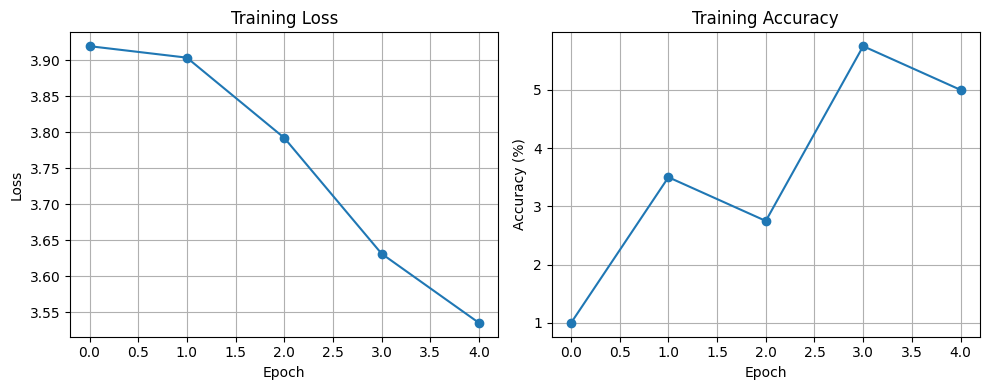

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history["loss"], marker="o")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history["accuracy"], marker="o")
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
uploaded = files.upload()
speech_path = next(iter(uploaded))

speech, speech_sr = librosa.load(
    speech_path, sr=16000, mono=True, duration=30
)

asr = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-tiny",
    device=0 if torch.cuda.is_available() else -1
)

stt_start = time.time()

stt_result = asr({
    "raw": speech,
    "sampling_rate": 16000
})

recognized_text = stt_result["text"].strip()
stt_time = time.time() - stt_start

print("Recognized text:", recognized_text)
print("STT processing time:", round(stt_time, 2), "seconds")

display(Audio(speech, rate=16000))

del asr
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Saving harvard.wav to harvard.wav


config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

...

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece token

Recognized text: The stale smell of old beer lingers. It takes heat to bring out the odor. A cold dip restores health in zest. A salt pickle tastes fine with ham. Tacos all pastora are my favorite. A zestful food is the hot cross bun.
STT processing time: 2.4 seconds


In [11]:
from jiwer import wer

reference_text = input(
    "Enter the exact words spoken in your recording: "
).strip()

if reference_text:
    word_error_rate = wer(
        reference_text.lower(),
        recognized_text.lower()
    )

    print(f"Word Error Rate (WER): {word_error_rate:.4f}")
    print(f"WER percentage: {word_error_rate * 100:.2f}%")
else:
    print("WER not calculated because no reference transcript was entered.")

Enter the exact words spoken in your recording: The stale smell of old beer lingers. It takes heat to bring out the odor. A cold dip restores health in zest. A salt pickle tastes fine with ham. Tacos all pastora are my favorite. A zestful food is the hot cross bun.
Word Error Rate (WER): 0.0000
WER percentage: 0.00%


In [12]:
from gtts import gTTS

tts_text = (
    f"The recognized speech is: {recognized_text}. "
    f"The predicted sound category is "
    f"{classes[y_pred[0]]}."
)

print("TTS text:", tts_text)

tts = gTTS(text=tts_text, lang="en")
tts.save("audio_classification_output.mp3")

display(Audio("audio_classification_output.mp3"))

files.download("audio_classification_output.mp3")

TTS text: The recognized speech is: The stale smell of old beer lingers. It takes heat to bring out the odor. A cold dip restores health in zest. A salt pickle tastes fine with ham. Tacos all pastora are my favorite. A zestful food is the hot cross bun.. The predicted sound category is rain.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
performance = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Macro Precision (%)",
        "Macro Recall (%)",
        "Macro F1-score (%)",
        "Training Time (seconds)",
        "Test Inference Time (seconds)",
        "STT Processing Time (seconds)",
        "Word Error Rate (%)"
    ],
    "Value": [
        round(accuracy * 100, 2),
        round(precision * 100, 2),
        round(recall * 100, 2),
        round(f1 * 100, 2),
        round(training_time, 2),
        round(inference_time, 2),
        round(stt_time, 2),
        round(word_error_rate * 100, 2)
        if reference_text else "Not evaluated"
    ]
})

print(performance)
performance.to_csv("audio_classification_results.csv", index=False)
files.download("audio_classification_results.csv")

                          Metric  Value
0                   Accuracy (%)  15.00
1            Macro Precision (%)   8.14
2               Macro Recall (%)  15.00
3             Macro F1-score (%)   8.51
4        Training Time (seconds)  45.35
5  Test Inference Time (seconds)   0.88
6  STT Processing Time (seconds)   2.40
7            Word Error Rate (%)   0.00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
performance = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Macro Precision (%)",
        "Macro Recall (%)",
        "Macro F1-score (%)",
        "Training Time (seconds)",
        "Test Inference Time (seconds)",
        "STT Processing Time (seconds)",
        "Word Error Rate (%)"
    ],
    "Value": [
        round(accuracy * 100, 2),
        round(precision * 100, 2),
        round(recall * 100, 2),
        round(f1 * 100, 2),
        round(training_time, 2),
        round(inference_time, 2),
        round(stt_time, 2),
        round(word_error_rate * 100, 2)
        if reference_text else "Not evaluated"
    ]
})

print(performance)
performance.to_csv("audio_classification_results.csv", index=False)
files.download("audio_classification_results.csv")

                          Metric  Value
0                   Accuracy (%)  15.00
1            Macro Precision (%)   8.14
2               Macro Recall (%)  15.00
3             Macro F1-score (%)   8.51
4        Training Time (seconds)  45.35
5  Test Inference Time (seconds)   0.88
6  STT Processing Time (seconds)   2.40
7            Word Error Rate (%)   0.00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>